In [2]:
%matplotlib inline

%reset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scikit_posthocs as sp
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.multitest as smm
from scipy import stats
from scipy.integrate import simpson
from scipy.stats import kruskal
from statannotations.Annotator import Annotator
from statsmodels.formula.api import mixedlm
from statsmodels.formula.api import ols
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests


import pickle
import sys
import warnings

warnings.filterwarnings('ignore')

sys.path.append("/Users/sambe/Documents/Python_Projects/FDA/functions")
import fNIRSData

Nothing done.


In [3]:
#User defined params

#for use in data manipulation/exploration
location = 'GM'
timePoints = [5, 8, 12]
numChroms = [1, 2]
method = 'FF' #'FPCA' or 'FF'
cptSignificance = 0.05 #alpha for determining the significance of a change point    
firstTrial = 1
lastTrial = 25
roiOnly = 1 #set to zero to analyse all detected changepoints

#Channel selection
# "Total" = use ROI channels for either chromophore
# "Both" = use channels in which change points have been detected in both chromophores for that age
# "Temporal" = use channels in which change points have been detected in both chromophores for that age
roiSelection = "Both" 

totalChans = 34
totalTimepoints = len(timePoints)

In [4]:
# Helper function to load data
def load_data(filename):
    with open(filename, 'rb') as f:
        return pickle.load(f)

In [5]:
# Channel mapping for plots later on
# channel mapping
mappingDict = {
    1: 15, 2: 18, 3: 12, 4: 16, 5: 19, 6: 34, 7: 37, 8: 31, 9: 35, 10: 38,
    11: 9, 12: 13, 13: 17, 14: 6, 15: 10, 16: 14, 17: 28, 18: 32, 19: 36,
    20: 25, 21: 29, 22: 33, 23: 3, 24: 7, 25: 11, 26: 22, 27: 26, 28: 30,
    29: 20, 30: 23, 31: 27, 32: 2, 33: 5, 34: 8
}

In [6]:
# Initialize dictionaries
firstChangePoints_dict = {}
lastChangePoints_dict = {}
decrChangePoints_dict = {}
firstAndDecrChangePoints_dict = {}
finalAndDecrChangePoints_dict = {}
latestDecrChangePoints_dict = {}
earliestDecrChangePoints_dict = {}
countPartChan_dict = {}
ageCPtDFs = {}


In [7]:
createdCountList = 0

for agePoint in timePoints:

    for numChrom in numChroms:

        if createdCountList == 0:
            cPtCount = np.zeros(totalChans)
            createdCountList = 1

        #chromophore name
        if numChrom == 1:
            chromName = 'HbO'
        elif numChrom == 2:
            chromName = 'HbR'
        else:
            chromName = 'HbT'

        cptFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/grpChangePointDFs/ChPt'+str(location)+str(agePoint)+'mo'+str(chromName)+method+'.pkl'

        # Load CPt data
        dfCPts = load_data(cptFilename)
        channels = np.unique(dfCPts['Channel'].values)

        for channel in range(totalChans):

            chanCPtFrame = dfCPts[dfCPts["Channel"] == channel]

            if not len(chanCPtFrame) == 0:
                cPtCount[channel-1] = cPtCount[channel-1] + 1

In [8]:
trialAUCsByAge = {age: {trialNum: [] for trialNum in range(1, lastTrial+1)} for age in timePoints}


for agePoint in timePoints:

    # File containing data for age and cohort
    recordingFrameFilename = '/Users/sambe/Documents/Python_Projects/FDA/dataRaw/homer2'+str(location)+str(agePoint)+'moDataFrame.pkl'

    # Load fNIRS data
    dfFull = load_data(recordingFrameFilename)

    # Find the dataframe column which contains the recorded time series
    indexTS = dfFull.columns.get_loc("Time series")

    # Filter the DataFrame with fNIRs data to remove chan and part combinations with any non-zero in specified columns
    group_keys = dfFull.groupby(['ID', 'Chrom', 'Channel']).filter(
        lambda x: (
            x['Trial presented'].ne(0).any() or
            x['Channel pruned'].ne(0).any() or
            x['Trial rejected'].ne(0).any() or
            x['Trial window cut'].ne(0).any()
        )
    )[['ID', 'Chrom', 'Channel']].drop_duplicates()

    # Merge to identify chann and participant combinations to keep
    dfFiltered = dfFull.merge(group_keys, on=['ID', 'Chrom', 'Channel'], how='left', indicator=True)
    dfFiltered = dfFiltered[dfFiltered['_merge'] == 'left_only'].drop(columns=['_merge'])

    #count number of participants whose data is used for each channel (for LMM/regr. analysis)
    countPartChan = dfFiltered[dfFiltered['Chrom'].isin([1, 2])]
    countPartChan = countPartChan.drop_duplicates(subset=['Chrom', 'Channel', 'ID'])
    countPartChan = countPartChan.groupby(['Channel', 'ID']).size().reset_index(name='Count')
    countPartChan = countPartChan.groupby('Channel').size().reset_index(name='Count')
    countPartChan = countPartChan['Count'].values.astype(int)
    countPartChan_dict[agePoint] = countPartChan

    for numChrom in numChroms:

        #chromophore name
        if numChrom == 1:
            chromName = 'HbO'
        elif numChrom == 2:
            chromName = 'HbR'
        else:
            chromName = 'HbT'

        # File containing calculated changepoints
        cptFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/grpChangePointDFs/ChPt'+str(location)+str(agePoint)+'mo'+str(chromName)+method+'.pkl'

        # Load CPt data
        dfCPts = load_data(cptFilename)

        # filter for ROI chans if required
        if roiOnly:
            if roiSelection.upper == "BOTH":
                roiChans = fNIRSData.getROI(agePoint, location)
                dfCPts = dfCPts[dfCPts['Channel'].isin(roiChans["Both"])]
            else:
                roiChans = []
                for age in timePoints:
                    chans = fNIRSData.getROI(age, location)
                    roiChans.extend(chans["Both"])
                roiChans = list(set(roiChans))
                dfCPts = dfCPts[dfCPts['Channel'].isin(roiChans)]

        # Impose ID list on DFs (used later)
        dfCPts.index = range(0, len(dfCPts))

        # Filter DF so that only stat. significant CPts remain
        # should already only be sig. points left but as a double check is included
        dfCPts = dfCPts[dfCPts['p-value'] <= cptSignificance]

        # Create column to indicate whether the magnitude of the mean response Decreases (1) or decreases (0) after the changepoint
        dfCPts['Decrease'] = 0

        # create column which will later contain count of age/chromophore combinations in which change points have been detected
        dfCPts["Change Point Count"] = 0

        # CPt DF specific variables for indexing/creating same-sized variables later
        channels = np.unique(dfCPts['Channel'].values)

        for numChan in channels:

            # Obtain CPt info for channel
            dfChan = (dfCPts[dfCPts['Channel'] == numChan]).sort_values(by=['Change Point'])
            changeColumn = (dfChan.get('Change Point').tolist())
            changeColumn = [int(x) for x in changeColumn]
            changeColumn.append(lastTrial + 1)

            # Query data from chosen channel
            dataMatrix = fNIRSData.groupDataMatrix(dfFull,
                                                numChan,
                                                numChrom,
                                                firstTrial,
                                                lastTrial)
        
            # Initialise variables for mean curve calculations betw. changeColumn
            iBlock = 0
            firstBlockTrial = 1
            blockMeans = np.empty([len(changeColumn), dfFull.iloc[0,indexTS].shape[0]])

            # Calculate mean trials between CPts
            for point in changeColumn:

                lastBlockTrial = point-1 #-1 because dataMatrix rows go from 0->(numTrials-1)
                blockMatrix = dataMatrix[firstBlockTrial-1:lastBlockTrial-1, ]
                blockMeans[iBlock] = np.mean(blockMatrix, axis = 0)
                firstBlockTrial = point
                iBlock = iBlock + 1
        
                # Calculate absolute block means
                absBlockMeans = np.abs(blockMeans)

                for i in range(1, len(changeColumn)):

                    #for inserting change size/type values into right place:
                    c1 = dfCPts['Channel'] == numChan
                    c2 = dfCPts['Change Point'] == changeColumn[i-1]

                    # Calculate 'piece' of volume between two current CPts
                    aucMeanTrialBefore = simpson(absBlockMeans[i-1,:], dx = 1)
                    aucMeanTrialAfter = simpson(absBlockMeans[i,:], dx = 1)

                    # Compute change size
                    changeSize = aucMeanTrialBefore - aucMeanTrialAfter
                    dfCPts.loc[c1 & c2, 'Change Size'] = changeSize

                    # Change the indicator in the 'Decrease' column if the magnitude of the response Decreases after the change point
                    if aucMeanTrialAfter < aucMeanTrialBefore:
                        dfCPts.loc[c1 & c2, 'Decrease'] = 1

                    #add change point count to relevant location
                    dfCPts.loc[c1 & c2, "Change Point Count"] = cPtCount[numChan-1]

            for i in range(blockMeans.shape[0]):
                auc = simpson(absBlockMeans[i,:], dx = 1)

                # Use changeColumn to assign trial range:
                if i == 0:
                    firstBlockTrial = 1
                    lastBlockTrial = changeColumn[0] - 1
                else:
                    firstBlockTrial = changeColumn[i-1]
                    lastBlockTrial = changeColumn[i] - 1

                # assign AUC to trials:
                for trial in range(firstBlockTrial, lastBlockTrial + 1):
                    trialAUCsByAge[agePoint][trial].append(auc)

        if numChrom == 1:
            dfCPtsHbO = dfCPts
        else:
            dfCPtsHbR = dfCPts
            dfCPts = pd.concat([dfCPtsHbO, dfCPtsHbR], ignore_index=True)

            # Add a column with the number of participants whose data contributed to
            # group mean curve for this channel
            dfCPts.insert(0, 'ParticipantCount', countPartChan_dict[agePoint][((dfCPts['Channel'].values)-1).astype(int)])

            # Add a column with the current age for use later in models/analysis
            dfCPts.insert(0, 'Age', agePoint)

            # Find IDs of first change points for each channel in the filtered DF
            idx = dfCPts.groupby('Channel')['Change Point'].idxmin()
            #Slice CPts DF with just these IDs
            dfFirstCPts = dfCPts.loc[idx]
            firstChangePoints_dict[agePoint] = dfFirstCPts

            # Find IDs of last change points for each channel in the filtered DF
            idx = dfCPts.groupby('Channel')['Change Point'].idxmax()
            #Slice CPts DF with just these IDs
            dfLastCPts = dfCPts.loc[idx]
            lastChangePoints_dict[agePoint] = dfLastCPts

            # Slice CPts DF containing only 'decreasing' changepoints
            dfDecreasingCPts = dfCPts[dfCPts['Decrease'] == 1]
            decrChangePoints_dict[agePoint] = dfDecreasingCPts

            #Slice CPts DF containing only first AND decreasing CPts
            dfIntersection = dfCPts[dfCPts.index.isin(dfFirstCPts.index) & dfCPts.index.isin(dfDecreasingCPts.index)]
            firstAndDecrChangePoints_dict[agePoint] = dfIntersection

            #Slice CPts DF containing only last AND decreasing CPts
            dfIntersection = dfCPts[dfCPts.index.isin(dfLastCPts.index) & dfCPts.index.isin(dfDecreasingCPts.index)]
            finalAndDecrChangePoints_dict[agePoint] = dfIntersection

            # Find IDs of last change points for each channel in the DF containing 
            # ONLY decreasing changepoints
            idx = dfDecreasingCPts.groupby('Channel')['Change Point'].idxmax()
            #Slice CPts DF with just these IDs
            dfLatestDecrCPts = dfDecreasingCPts.loc[idx]
            latestDecrChangePoints_dict[agePoint] = dfLatestDecrCPts

            # Find IDs of first change points for each channel in the DF containing 
            # ONLY decreasing changepoints
            idx = dfDecreasingCPts.groupby('Channel')['Change Point'].idxmin()
            #Slice CPts DF with just these IDs
            dfEarliestDecrCPts = dfDecreasingCPts.loc[idx]
            earliestDecrChangePoints_dict[agePoint] = dfEarliestDecrCPts

            # to view CPts dataframe in nicer format 
            dfAgeName = f"CPt Dataframe: {agePoint}mo"
            ageCPtDFs[dfAgeName] = dfCPts

# Create DFs combining data from all ages
all_firstChangePoints = pd.concat(firstChangePoints_dict, ignore_index=True)
all_lastChangePoints = pd.concat(lastChangePoints_dict, ignore_index=True)
all_decrChangePoints = pd.concat(decrChangePoints_dict, ignore_index=True)
all_firstAndDecrChangePoints = pd.concat(firstAndDecrChangePoints_dict, ignore_index=True)
all_finalAndDecrChangePoints = pd.concat(finalAndDecrChangePoints_dict, ignore_index=True)
all_latestDecrChangePoints = pd.concat(latestDecrChangePoints_dict, ignore_index=True)
all_earliestDecrChangePoints = pd.concat(earliestDecrChangePoints_dict, ignore_index=True)


In [9]:
iAge = 0

for name, value in ageCPtDFs.items():

    if roiOnly == 0:

        cptFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/grpChangePointDFs/combinedChPt'+str(location)+str(timePoints[iAge])+'mo'+method+'.pkl'

    else:

        if roiSelection == "Total":

            cptFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/grpChangePointDFs/combinedROITotalChPt'+str(location)+str(timePoints[iAge])+'mo'+method+'.pkl'

        elif roiSelection == "Both":

            cptFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/grpChangePointDFs/combinedROIBothChPt'+str(location)+str(timePoints[iAge])+'mo'+method+'.pkl'

        else:

            cptFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/grpChangePointDFs/combinedROITemporalChPt'+str(location)+str(timePoints[iAge])+'mo'+method+'.pkl'



    #save the ChPt dataframe
    with open(cptFilename, 'wb') as f:
        pickle.dump(value, f)

    iAge+=1

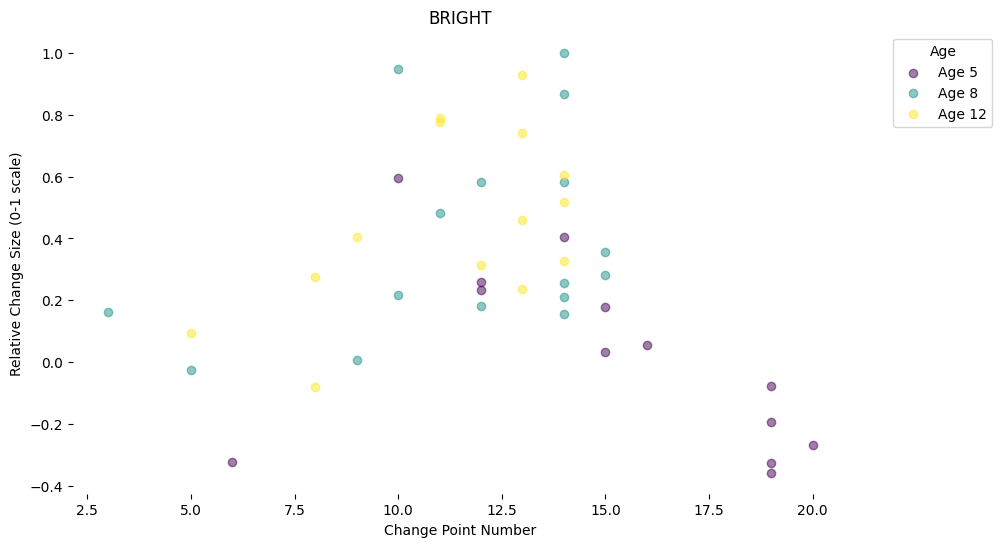

In [15]:
# Concatenate all age data
dfAllAges = pd.concat(ageCPtDFs.values(), ignore_index=True)

# Find the largest Change Size across all ages
max_change_size = dfAllAges["Change Size"].max()

# Define unique age values and a colormap
unique_ages = dfAllAges["Age"].unique()
colors = plt.cm.viridis(np.linspace(0, 1, len(unique_ages)))  # Get distinct colors

# Create figure
plt.figure(figsize=(10, 6))

# Plot each age group separately with a specific color
for age, color in zip(unique_ages, colors):
    subset = dfAllAges[dfAllAges["Age"] == age]
    relative_change_size = subset["Change Size"] / max_change_size
    plt.scatter(subset["Change Point"], relative_change_size, color=color, label=f"Age {age}", alpha=0.5)

plt.xlabel("Change Point Number")
plt.ylabel("Relative Change Size (0-1 scale)")
plt.title("BRIGHT")

# Aesthetic tweaks
ax = plt.gca()  # Get current axis
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)

# Add a legend instead of a colorbar
plt.legend(title="Age", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.show()


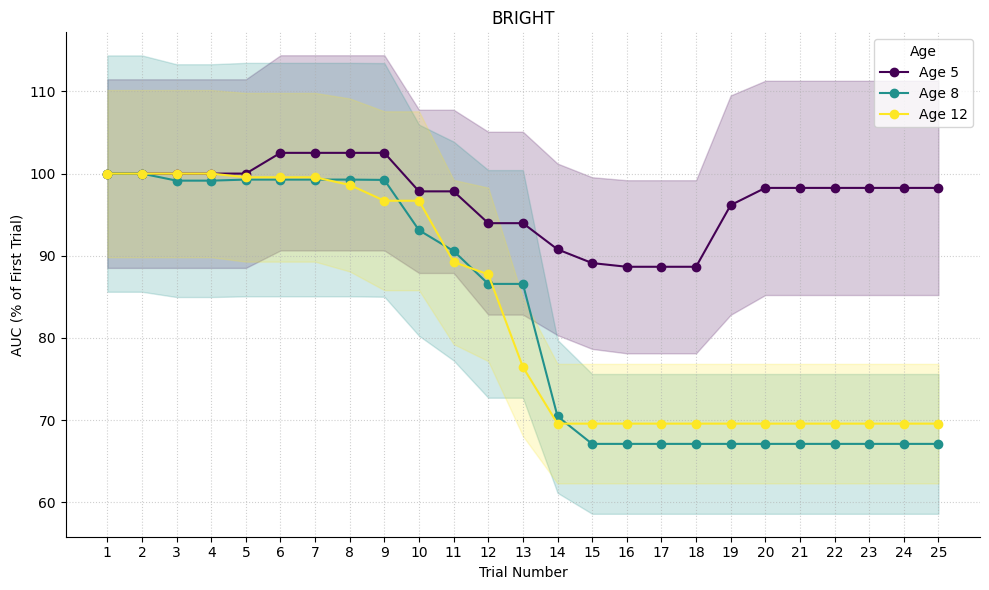

In [14]:
plt.figure(figsize=(10,6))
colors = plt.cm.viridis(np.linspace(0, 1, len(unique_ages)))

for age, color in zip(timePoints, colors):
    trialNums = sorted(trialAUCsByAge[age].keys())
    
    meanAUCs = []
    semAUCs = []

    for t in trialNums:
        values = trialAUCsByAge[age][t]
        if values:
            meanAUCs.append(np.mean(values))
            semAUCs.append(np.std(values) / np.sqrt(len(values)))  # SEM
        else:
            meanAUCs.append(np.nan)
            semAUCs.append(np.nan)

    meanAUCs = np.array(meanAUCs)
    semAUCs = np.array(semAUCs)

    # Compute % of baseline  first trial AUC)
    baselineAUC = meanAUCs[0]
    percentOfBaseline = (meanAUCs / baselineAUC) * 100
    percentSEM = (semAUCs / baselineAUC) * 100

    # Plot
    plt.plot(trialNums, percentOfBaseline, marker='o', label=f'Age {age}', color=color)
    plt.fill_between(trialNums, 
                     percentOfBaseline - percentSEM, 
                     percentOfBaseline + percentSEM, 
                     color=color, alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('AUC (% of First Trial)')
plt.title('BRIGHT')
plt.grid(True, linestyle=':', linewidth=0.8, alpha=0.6) 
plt.xticks(np.arange(1, lastTrial+1))
plt.legend(title='Age')
plt.tight_layout()
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()


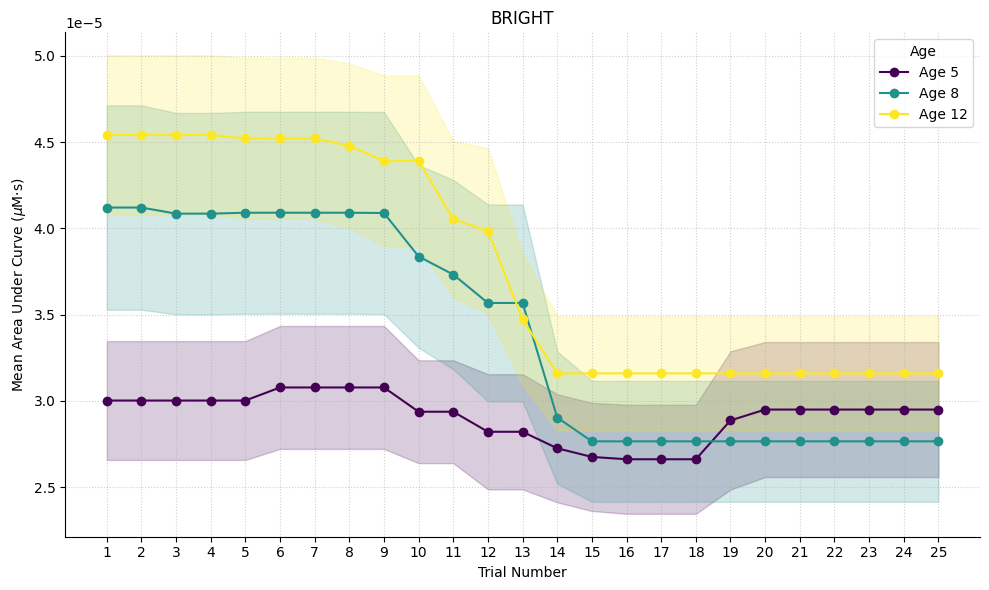

In [12]:
plt.figure(figsize=(10,6))
colors = plt.cm.viridis(np.linspace(0, 1, len(unique_ages)))

for age, color in zip(timePoints, colors):
    trialNums = sorted(trialAUCsByAge[age].keys())
    
    meanAUCs = []
    semAUCs = []

    for t in trialNums:
        values = trialAUCsByAge[age][t]
        if values:
            meanAUCs.append(np.mean(values))
            semAUCs.append(np.std(values) / np.sqrt(len(values)))  # SEM
        else:
            meanAUCs.append(np.nan)
            semAUCs.append(np.nan)

    plt.plot(trialNums, meanAUCs, marker='o', label=f'Age {age}', color=color)
    plt.fill_between(trialNums, 
                     np.array(meanAUCs) - np.array(semAUCs), 
                     np.array(meanAUCs) + np.array(semAUCs), 
                     color=color, alpha=0.2)

plt.xlabel('Trial Number')
plt.ylabel('Mean Area Under Curve ($\mu$M$\cdot$s)')
plt.title('BRIGHT')
plt.grid(True, linestyle=':', linewidth=0.8, alpha=0.6) 
plt.xticks(np.arange(1, lastTrial+1))
plt.legend(title='Age')
plt.tight_layout()
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()


In [188]:
## Print dictionaries if needed
# print(lastDetect_dict)
# print(lastChanChanges_dict)
# print(finalAndDecrDetect_dict)
# print(finalAndDecrChanChanges_dict)
# print(latestDecrDetect_dict)
# print(latestDecrChanChanges_dict)

In [189]:
# First CPt data - weighted logistic regression, Post-hoc tests, multiple comparisons and Effect size calculations
print("STATISTICAL ANALYSIS FOR: First CPt data")
print(" ")

# GENERATE DATA IN REQUISITE FORM
# Assuming data already in the format described, modify as needed

# Create count of participants' contributions to each channel data
count = np.empty(len(all_firstChangePoints))
for i in range(0, len(all_firstChangePoints)):
    iAge = all_firstChangePoints.iloc[i]['Age']
    iChan = all_firstChangePoints.iloc[i]['Channel']
    count[i] = countPartChan_dict[iAge][iChan-1].astype(int)

data = {
    'Channel': all_firstChangePoints['Channel'].values.astype(int),
    'Timepoint': all_firstChangePoints['Age'].values.astype(int),
    'ChangepointTrial': all_firstChangePoints['Change Point'].values.astype(int),
    'NumberOfParticipants': count,
    'Change Point Count': all_firstChangePoints['Change Point Count'].values.astype(int)
}

# Create DataFrame
df = pd.DataFrame(data)

# # Print sample of the generated data (to check!)
# print("Sample of Generated Data:")
# print(df.head())
# print()

# Ordinal Logistic Regression with weights
model_ologit = OrderedModel(df['ChangepointTrial'], 
                            df[['Timepoint', 'Change Point Count']], 
                            weights=df['NumberOfParticipants'], 
                            distr='logit')
result_ologit = model_ologit.fit(method='bfgs')

# Print original results for the weighted ordinal logistic regression
print("Weighted Ordinal Logistic Regression:")
print(result_ologit.summary()) #full
print()

# # Correct effect of timepoint for multiple comparisons
# pvalues = result_ologit.pvalues
# alpha = 0.05
# reject, pvals_corrected, _, _ = multipletests(pvalues, alpha=alpha, method='bonferroni')
# print("Bonferroni corrected p-value for Age ('Timepoint'):")
# print(pvals_corrected[0])
# print()

# Perform Wald test for the 'Timepoint' coefficient
wald_test_timepoint = result_ologit.wald_test('Timepoint')
print("Outcome of conducting a post-hoc Wald test:")
print("(to confirm that age has a significant effect on the changepoints detected)")
print(wald_test_timepoint)
print()

# Fit an OLS model for ANOVA
anova_model = ols('ChangepointTrial ~ C(Timepoint)', data=df).fit()

# Perform Tukey's HSD test for multiple comparisons
tukey_results = pairwise_tukeyhsd(endog=df['ChangepointTrial'], 
                                  groups=df['Timepoint'], 
                                  alpha=0.05)
print(tukey_results)


# # Predict probabilities for each category
# pred_probs = result_ologit.predict()

# # Add predicted probabilities to the DataFrame
# df['Predicted_Probabilities'] = pred_probs.tolist()

# # Example: Calculate marginal effects for a specific Timepoint (say, 5)
# df_timepoint_5 = df[df['Timepoint'] == 5].copy()

# # Predict probabilities for Timepoint 5
# pred_probs_timepoint_5 = result_ologit.predict(df_timepoint_5[['Timepoint', 'Channel']])

# # Calculate the difference in predicted probabilities for Timepoint 5
# marginal_effect_timepoint_5 = pred_probs_timepoint_5.mean(axis=0) - pred_probs.mean(axis=0)

# print(f"Marginal Effects for Timepoint 5:\n{marginal_effect_timepoint_5}")

STATISTICAL ANALYSIS FOR: First CPt data
 
Optimization terminated successfully.
         Current function value: 2.402182
         Iterations: 36
         Function evaluations: 38
         Gradient evaluations: 38
Weighted Ordinal Logistic Regression:
                             OrderedModel Results                             
Dep. Variable:       ChangepointTrial   Log-Likelihood:                -50.446
Model:                   OrderedModel   AIC:                             128.9
Method:            Maximum Likelihood   BIC:                             143.5
Date:                Sun, 23 Feb 2025                                         
Time:                        16:50:04                                         
No. Observations:                  21                                         
Df Residuals:                       7                                         
Df Model:                           2                                         
                         coef    std

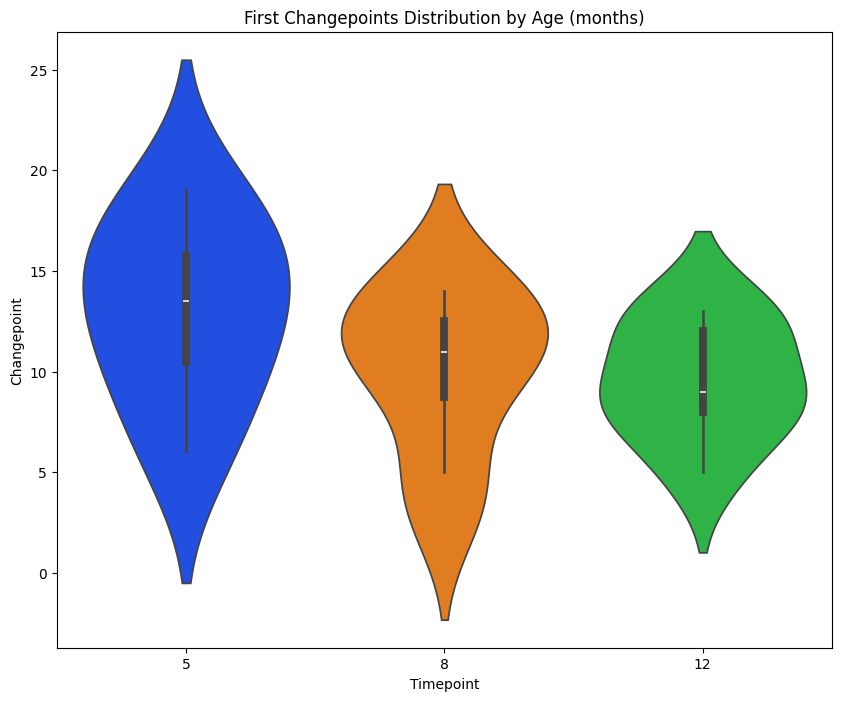

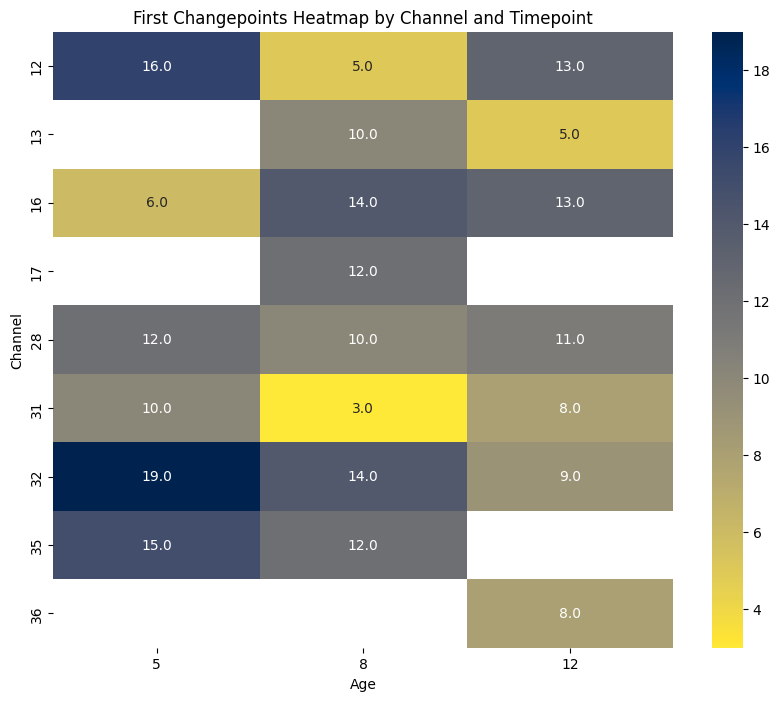

In [190]:
# Violin plot and heatmaps for first change points across ages

#VIOLIN PLOT
# Filter out rows where ChangepointTrial is 0 or NaN
df_filtered = df.dropna(subset=['ChangepointTrial']).loc[df['ChangepointTrial'] != 0]
# Colorblind-friendly palette for violin plot
palette_violin = sns.color_palette("bright", 3)
# Plot violin plot 
plt.figure(figsize=(10, 8))
sns.violinplot(x='Timepoint', y='ChangepointTrial', data=df_filtered, palette=palette_violin)
plt.title('First Changepoints Distribution by Age (months)')
plt.ylabel('Changepoint')
plt.show()


# HEATMAP
# Replace 'Channel' numbers with 'BRIGHT' labels
df['BRIGHT'] = df['Channel'].map(mappingDict)
# Pivot table for heatmap using BRIGHT labels
pivot_table = df.pivot_table(index='BRIGHT', columns='Timepoint', values='ChangepointTrial', aggfunc=np.mean)
# Replace 0s with NaNs
pivot_table_no_zeros = pivot_table.replace(0, np.nan)
# Sort rows based on BRIGHT numbering
pivot_table_no_zeros = pivot_table_no_zeros.sort_index()
# Colorblind-friendly palette for heatmap
paletteHeatmap = 'cividis_r' 
# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(pivot_table_no_zeros, cmap=paletteHeatmap, annot=True, fmt='.1f', cbar=True)
plt.title('First Changepoints Heatmap by Channel and Timepoint')
plt.xlabel('Age')
plt.ylabel('Channel')
plt.show()

In [191]:
# Final CPt data - weighted logistic regression, Post-hoc tests, multiple comparisons and Effect size calculations
print("STATISTICAL ANALYSIS FOR: Final CPt data")
print(" ")

# GENERATE DATA IN REQUISITE FORM
# Assuming data already in the format described, modify as needed

# Create count of participants' contributions to each channel data
count = np.empty(len(all_lastChangePoints))
for i in range(0, len(all_lastChangePoints)):
    iAge = all_lastChangePoints.iloc[i]['Age']
    iChan = all_lastChangePoints.iloc[i]['Channel']
    count[i] = countPartChan_dict[iAge][iChan-1].astype(int)

data = {
    'Channel': all_lastChangePoints['Channel'].values.astype(int),
    'Timepoint': all_lastChangePoints['Age'].values.astype(int),
    'ChangepointTrial': all_lastChangePoints['Change Point'].values.astype(int),
    'NumberOfParticipants': count,
    'Change Point Count': all_lastChangePoints['Change Point Count'].values.astype(int)
}

# Create DataFrame
df = pd.DataFrame(data)

# # Print sample of the generated data (to check!)
# print("Sample of Generated Data:")
# print(df.head())
# print()

# Ordinal Logistic Regression with weights
model_ologit = OrderedModel(df['ChangepointTrial'], 
                            df[['Timepoint', 'Change Point Count']], 
                            weights=df['NumberOfParticipants'], 
                            distr='logit')
result_ologit = model_ologit.fit(method='bfgs')

# Print original results for the weighted ordinal logistic regression
print("Weighted Ordinal Logistic Regression:")
print(result_ologit.summary()) #full
print()

# # Correct effect of timepoint for multiple comparisons
# pvalues = result_ologit.pvalues
# alpha = 0.05
# reject, pvals_corrected, _, _ = multipletests(pvalues, alpha=alpha, method='bonferroni')
# print("Bonferroni corrected p-value for Age ('Timepoint'):")
# print(pvals_corrected[0])
# print()

# Perform Wald test for the 'Timepoint' coefficient
wald_test_timepoint = result_ologit.wald_test('Timepoint')
print("Outcome of conducting a post-hoc Wald test:")
print("(to confirm that age has a significant effect on the changepoints detected)")
print(wald_test_timepoint)
print()

# Fit an OLS model for ANOVA
anova_model = ols('ChangepointTrial ~ C(Timepoint)', data=df).fit()

# Perform Tukey's HSD test for multiple comparisons
tukey_results = pairwise_tukeyhsd(endog=df['ChangepointTrial'], 
                                  groups=df['Timepoint'], 
                                  alpha=0.05)
print(tukey_results)


# # Predict probabilities for each category
# pred_probs = result_ologit.predict()

# # Add predicted probabilities to the DataFrame
# df['Predicted_Probabilities'] = pred_probs.tolist()

# # Example: Calculate marginal effects for a specific Timepoint (say, 5)
# df_timepoint_5 = df[df['Timepoint'] == 5].copy()

# # Predict probabilities for Timepoint 5
# pred_probs_timepoint_5 = result_ologit.predict(df_timepoint_5[['Timepoint', 'Channel']])

# # Calculate the difference in predicted probabilities for Timepoint 5
# marginal_effect_timepoint_5 = pred_probs_timepoint_5.mean(axis=0) - pred_probs.mean(axis=0)

# print(f"Marginal Effects for Timepoint 5:\n{marginal_effect_timepoint_5}")


STATISTICAL ANALYSIS FOR: Final CPt data
 
Optimization terminated successfully.
         Current function value: 1.445136
         Iterations: 35
         Function evaluations: 37
         Gradient evaluations: 37
Weighted Ordinal Logistic Regression:
                             OrderedModel Results                             
Dep. Variable:       ChangepointTrial   Log-Likelihood:                -30.348
Model:                   OrderedModel   AIC:                             78.70
Method:            Maximum Likelihood   BIC:                             88.10
Date:                Sun, 23 Feb 2025                                         
Time:                        16:50:05                                         
No. Observations:                  21                                         
Df Residuals:                      12                                         
Df Model:                           2                                         
                         coef    std

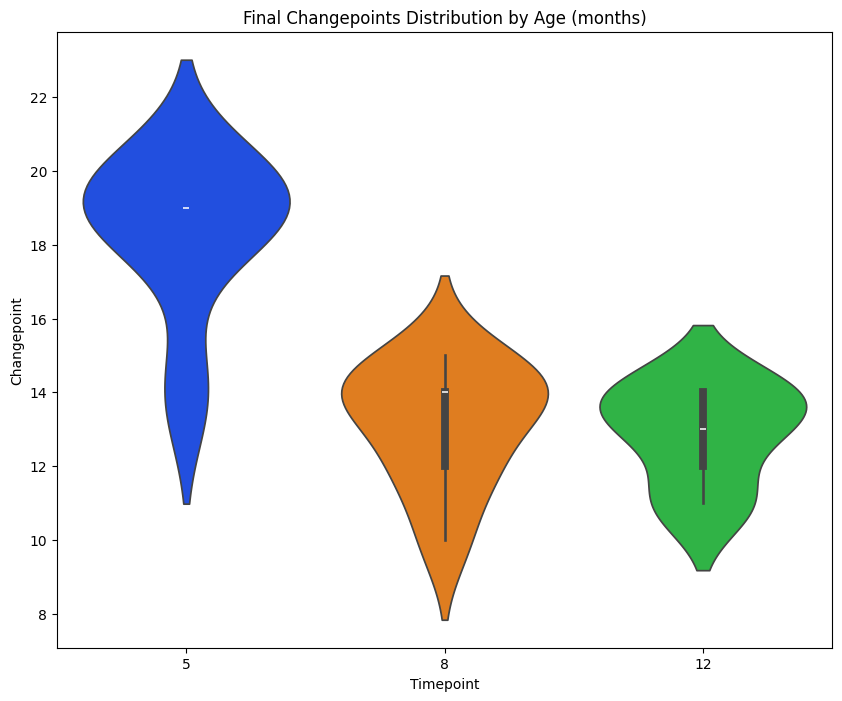

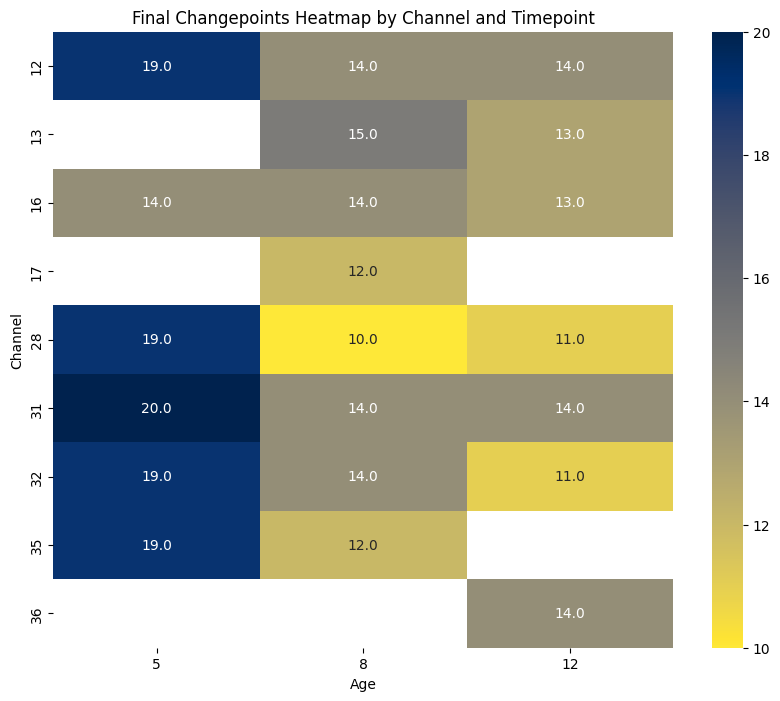

In [192]:
# Violin plot and heatmaps for final change points across ages

#VIOLIN PLOT
# Filter out rows where ChangepointTrial is 0 or NaN
df_filtered = df.dropna(subset=['ChangepointTrial']).loc[df['ChangepointTrial'] != 0]
# Colorblind-friendly palette for violin plot
palette_violin = sns.color_palette("bright", 3)
# Plot violin plot 
plt.figure(figsize=(10, 8))
sns.violinplot(x='Timepoint', y='ChangepointTrial', data=df_filtered, palette=palette_violin)
plt.title('Final Changepoints Distribution by Age (months)')
plt.ylabel('Changepoint')
plt.show()


# HEATMAP
# Replace 'Channel' numbers with 'BRIGHT' labels
df['BRIGHT'] = df['Channel'].map(mappingDict)
# Pivot table for heatmap using BRIGHT labels
pivot_table = df.pivot_table(index='BRIGHT', columns='Timepoint', values='ChangepointTrial', aggfunc=np.mean)
# Replace 0s with NaNs
pivot_table_no_zeros = pivot_table.replace(0, np.nan)
# Sort rows based on BRIGHT numbering
pivot_table_no_zeros = pivot_table_no_zeros.sort_index()
# Colorblind-friendly palette for heatmap
paletteHeatmap = 'cividis_r' 
# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(pivot_table_no_zeros, cmap=paletteHeatmap, annot=True, fmt='.1f', cbar=True)
plt.title('Final Changepoints Heatmap by Channel and Timepoint')
plt.xlabel('Age')
plt.ylabel('Channel')
plt.show()

In [193]:
# Decreasing CPt data  - weighted logistic regression, Post-hoc tests, multiple comparisons and Effect size calculations
print("STATISTICAL ANALYSIS FOR: Decreasing CPt data")
print(" ")

# GENERATE DATA IN REQUISITE FORM
# Assuming data already in the format described, modify as needed

# Create count of participants' contributions to each channel data
count = np.empty(len(all_decrChangePoints))
for i in range(0, len(all_decrChangePoints)):
    iAge = all_decrChangePoints.iloc[i]['Age']
    iChan = all_decrChangePoints.iloc[i]['Channel']
    count[i] = countPartChan_dict[iAge][iChan-1].astype(int)

data = {
    'Channel': all_decrChangePoints['Channel'].values.astype(int),
    'Timepoint': all_decrChangePoints['Age'].values.astype(int),
    'ChangepointTrial': all_decrChangePoints['Change Point'].values.astype(int),
    'NumberOfParticipants': count,
    'Change Point Count': all_decrChangePoints['Change Point Count'].values.astype(int)
}

# Create DataFrame
df = pd.DataFrame(data)

# # Print sample of the generated data (to check!)
# print("Sample of Generated Data:")
# print(df.head())
# print()

# Ordinal Logistic Regression with weights
model_ologit = OrderedModel(df['ChangepointTrial'], 
                            df[['Timepoint', 'Change Point Count']], 
                            weights=df['NumberOfParticipants'], 
                            distr='logit')
result_ologit = model_ologit.fit(method='bfgs')

# Print original results for the weighted ordinal logistic regression
print("Weighted Ordinal Logistic Regression:")
print(result_ologit.summary()) #full
print()

# # Correct effect of timepoint for multiple comparisons
# pvalues = result_ologit.pvalues
# alpha = 0.05
# reject, pvals_corrected, _, _ = multipletests(pvalues, alpha=alpha, method='bonferroni')
# print("Bonferroni corrected p-value for Age ('Timepoint'):")
# print(pvals_corrected[0])
# print()

# Perform Wald test for the 'Timepoint' coefficient
wald_test_timepoint = result_ologit.wald_test('Timepoint')
print("Outcome of conducting a post-hoc Wald test:")
print("(to confirm that age has a significant effect on the changepoints detected)")
print(wald_test_timepoint)
print()

# Fit an OLS model for ANOVA
anova_model = ols('ChangepointTrial ~ C(Timepoint)', data=df).fit()

# Perform Tukey's HSD test for multiple comparisons
tukey_results = pairwise_tukeyhsd(endog=df['ChangepointTrial'], 
                                  groups=df['Timepoint'], 
                                  alpha=0.05)
print(tukey_results)


# # Predict probabilities for each category
# pred_probs = result_ologit.predict()

# # Add predicted probabilities to the DataFrame
# df['Predicted_Probabilities'] = pred_probs.tolist()

# # Example: Calculate marginal effects for a specific Timepoint (say, 5)
# df_timepoint_5 = df[df['Timepoint'] == 5].copy()

# # Predict probabilities for Timepoint 5
# pred_probs_timepoint_5 = result_ologit.predict(df_timepoint_5[['Timepoint', 'Channel']])

# # Calculate the difference in predicted probabilities for Timepoint 5
# marginal_effect_timepoint_5 = pred_probs_timepoint_5.mean(axis=0) - pred_probs.mean(axis=0)

# print(f"Marginal Effects for Timepoint 5:\n{marginal_effect_timepoint_5}")



STATISTICAL ANALYSIS FOR: Decreasing CPt data
 
Optimization terminated successfully.
         Current function value: 2.213138
         Iterations: 45
         Function evaluations: 47
         Gradient evaluations: 47
Weighted Ordinal Logistic Regression:
                             OrderedModel Results                             
Dep. Variable:       ChangepointTrial   Log-Likelihood:                -81.886
Model:                   OrderedModel   AIC:                             191.8
Method:            Maximum Likelihood   BIC:                             214.3
Date:                Sun, 23 Feb 2025                                         
Time:                        16:50:05                                         
No. Observations:                  37                                         
Df Residuals:                      23                                         
Df Model:                           2                                         
                         coef  

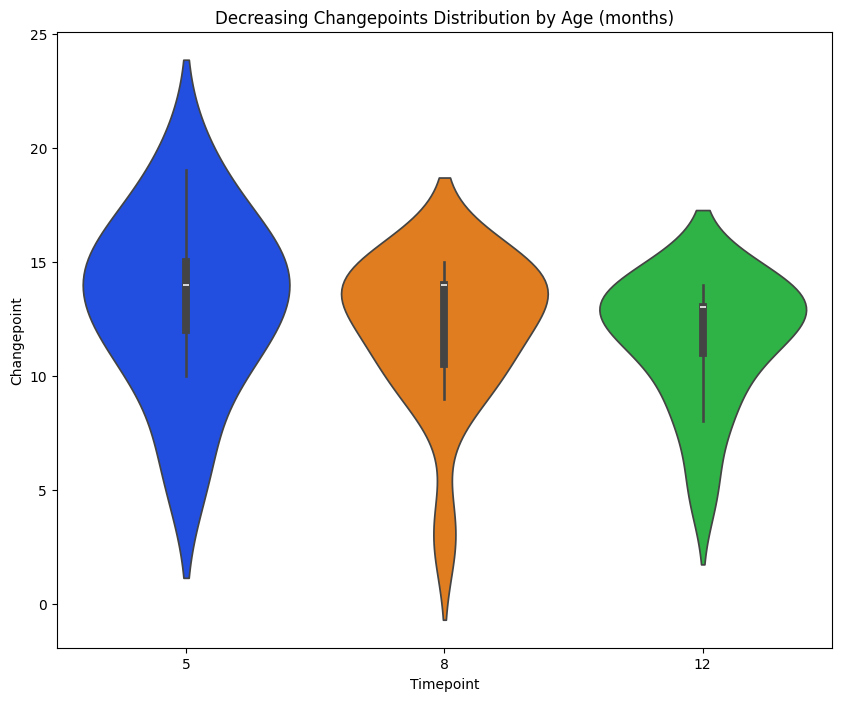

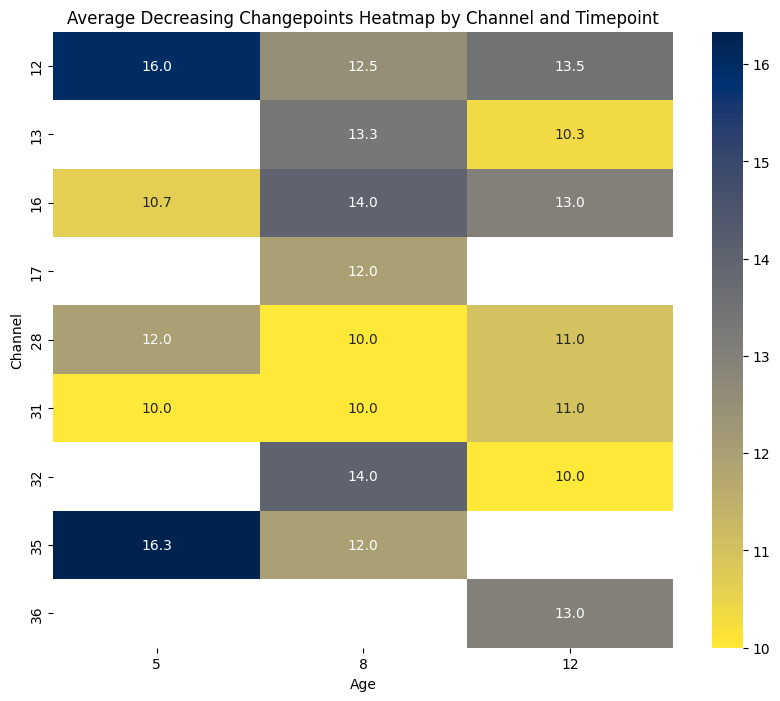

In [194]:
# Violin plot and heatmaps for decreasing change points across ages

#VIOLIN PLOT
# Filter out rows where ChangepointTrial is 0 or NaN
df_filtered = df.dropna(subset=['ChangepointTrial']).loc[df['ChangepointTrial'] != 0]
# Colorblind-friendly palette for violin plot
palette_violin = sns.color_palette("bright", 3)
# Plot violin plot 
plt.figure(figsize=(10, 8))
sns.violinplot(x='Timepoint', y='ChangepointTrial', data=df_filtered, palette=palette_violin)
plt.title('Decreasing Changepoints Distribution by Age (months)')
plt.ylabel('Changepoint')
plt.show()


# HEATMAP
# Replace 'Channel' numbers with 'BRIGHT' labels
df['BRIGHT'] = df['Channel'].map(mappingDict)
# Pivot table for heatmap using BRIGHT labels
pivot_table = df.pivot_table(index='BRIGHT', columns='Timepoint', values='ChangepointTrial', aggfunc=np.mean)
# Replace 0s with NaNs
pivot_table_no_zeros = pivot_table.replace(0, np.nan)
# Sort rows based on BRIGHT numbering
pivot_table_no_zeros = pivot_table_no_zeros.sort_index()
# Colorblind-friendly palette for heatmap
paletteHeatmap = 'cividis_r' 
# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(pivot_table_no_zeros, cmap=paletteHeatmap, annot=True, fmt='.1f', cbar=True)
plt.title('Average Decreasing Changepoints Heatmap by Channel and Timepoint')
plt.xlabel('Age')
plt.ylabel('Channel')
plt.show()

In [195]:
# First AND Decreasing CPt data  - weighted logistic regression, Post-hoc tests, multiple comparisons and Effect size calculations
print("STATISTICAL ANALYSIS FOR: First AND decreasing CPt data")
print(" ")

# GENERATE DATA IN REQUISITE FORM
# Assuming data already in the format described, modify as needed

# Create count of participants' contributions to each channel data
count = np.empty(len(all_firstAndDecrChangePoints))
for i in range(0, len(all_firstAndDecrChangePoints)):
    iAge = all_firstAndDecrChangePoints.iloc[i]['Age']
    iChan = all_firstAndDecrChangePoints.iloc[i]['Channel']
    count[i] = countPartChan_dict[iAge][iChan-1].astype(int)

data = {
    'Channel': all_firstAndDecrChangePoints['Channel'].values.astype(int),
    'Timepoint': all_firstAndDecrChangePoints['Age'].values.astype(int),
    'ChangepointTrial': all_firstAndDecrChangePoints['Change Point'].values.astype(int),
    'NumberOfParticipants': count,
    'Change Point Count': all_firstAndDecrChangePoints['Change Point Count'].values.astype(int)
}

# Create DataFrame
df = pd.DataFrame(data)

# # Print sample of the generated data (to check!)
# print("Sample of Generated Data:")
# print(df.head())
# print()

# Ordinal Logistic Regression with weights
model_ologit = OrderedModel(df['ChangepointTrial'], 
                            df[['Timepoint', 'Change Point Count']], 
                            weights=df['NumberOfParticipants'], 
                            distr='logit')
result_ologit = model_ologit.fit(method='bfgs')

# Print original results for the weighted ordinal logistic regression
print("Weighted Ordinal Logistic Regression:")
print(result_ologit.summary()) #full
print()

# # Correct effect of timepoint for multiple comparisons
# pvalues = result_ologit.pvalues
# alpha = 0.05
# reject, pvals_corrected, _, _ = multipletests(pvalues, alpha=alpha, method='bonferroni')
# print("Bonferroni corrected p-value for Age ('Timepoint'):")
# print(pvals_corrected[0])
# print()

# Perform Wald test for the 'Timepoint' coefficient
wald_test_timepoint = result_ologit.wald_test('Timepoint')
print("Outcome of conducting a post-hoc Wald test:")
print("(to confirm that age has a significant effect on the changepoints detected)")
print(wald_test_timepoint)
print()

# Fit an OLS model for ANOVA
anova_model = ols('ChangepointTrial ~ C(Timepoint)', data=df).fit()

# Perform Tukey's HSD test for multiple comparisons
tukey_results = pairwise_tukeyhsd(endog=df['ChangepointTrial'], 
                                  groups=df['Timepoint'], 
                                  alpha=0.05)
print(tukey_results)


# # Predict probabilities for each category
# pred_probs = result_ologit.predict()

# # Add predicted probabilities to the DataFrame
# df['Predicted_Probabilities'] = pred_probs.tolist()

# # Example: Calculate marginal effects for a specific Timepoint (say, 5)
# df_timepoint_5 = df[df['Timepoint'] == 5].copy()

# # Predict probabilities for Timepoint 5
# pred_probs_timepoint_5 = result_ologit.predict(df_timepoint_5[['Timepoint', 'Channel']])

# # Calculate the difference in predicted probabilities for Timepoint 5
# marginal_effect_timepoint_5 = pred_probs_timepoint_5.mean(axis=0) - pred_probs.mean(axis=0)

# print(f"Marginal Effects for Timepoint 5:\n{marginal_effect_timepoint_5}")



STATISTICAL ANALYSIS FOR: First AND decreasing CPt data
 
Optimization terminated successfully.
         Current function value: 2.327992
         Iterations: 35
         Function evaluations: 37
         Gradient evaluations: 37
Weighted Ordinal Logistic Regression:
                             OrderedModel Results                             
Dep. Variable:       ChangepointTrial   Log-Likelihood:                -41.904
Model:                   OrderedModel   AIC:                             109.8
Method:            Maximum Likelihood   BIC:                             121.4
Date:                Sun, 23 Feb 2025                                         
Time:                        16:50:06                                         
No. Observations:                  18                                         
Df Residuals:                       5                                         
Df Model:                           2                                         
                     

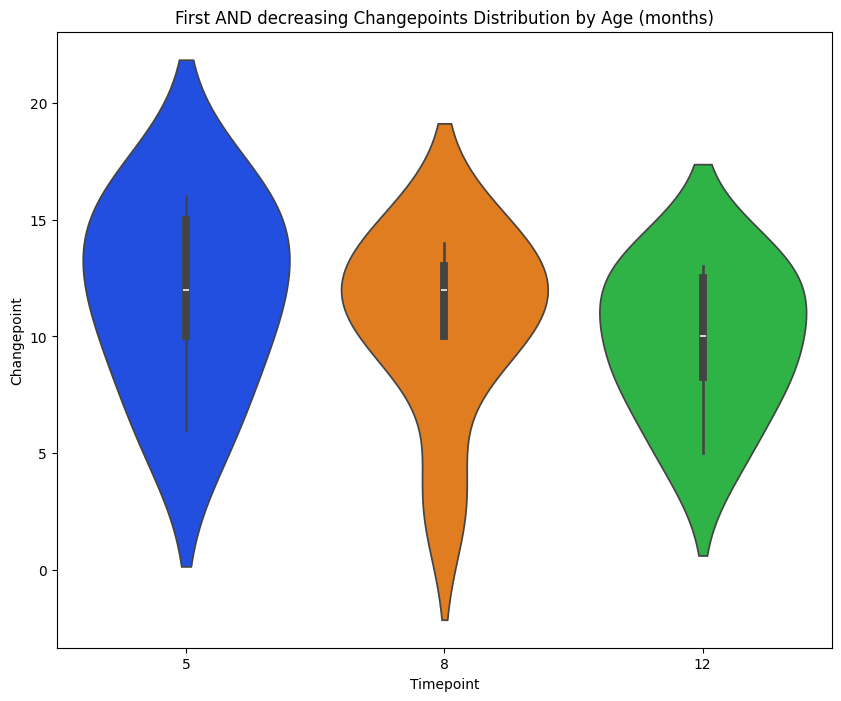

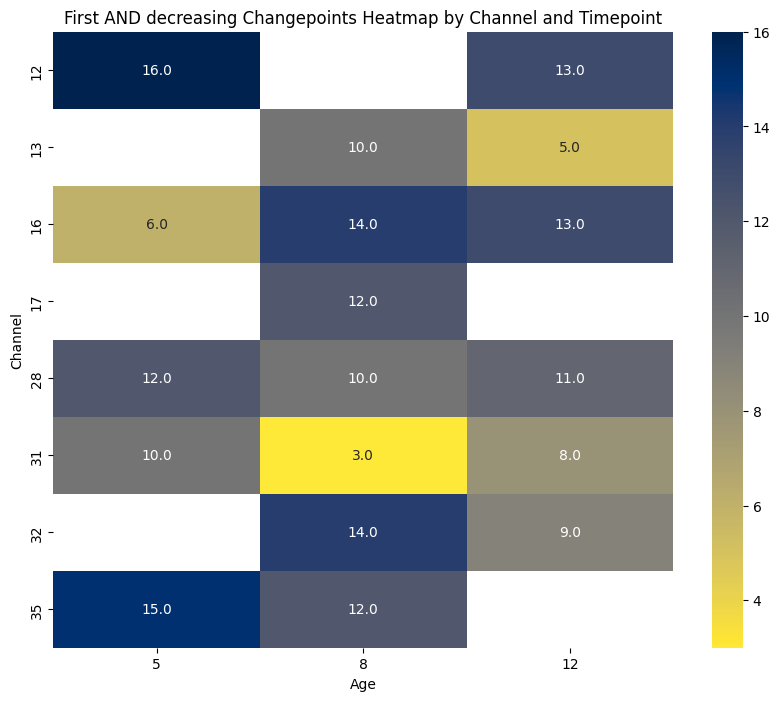

In [196]:
# Violin plot and heatmaps for first AND decreasing AND first change points across ages

#VIOLIN PLOT
# Filter out rows where ChangepointTrial is 0 or NaN
df_filtered = df.dropna(subset=['ChangepointTrial']).loc[df['ChangepointTrial'] != 0]
# Colorblind-friendly palette for violin plot
palette_violin = sns.color_palette("bright", 3)
# Plot violin plot 
plt.figure(figsize=(10, 8))
sns.violinplot(x='Timepoint', y='ChangepointTrial', data=df_filtered, palette=palette_violin)
plt.title('First AND decreasing Changepoints Distribution by Age (months)')
plt.ylabel('Changepoint')
plt.show()


# HEATMAP
# Replace 'Channel' numbers with 'BRIGHT' labels
df['BRIGHT'] = df['Channel'].map(mappingDict)
# Pivot table for heatmap using BRIGHT labels
pivot_table = df.pivot_table(index='BRIGHT', columns='Timepoint', values='ChangepointTrial', aggfunc=np.mean)
# Replace 0s with NaNs
pivot_table_no_zeros = pivot_table.replace(0, np.nan)
# Sort rows based on BRIGHT numbering
pivot_table_no_zeros = pivot_table_no_zeros.sort_index()
# Colorblind-friendly palette for heatmap
paletteHeatmap = 'cividis_r' 
# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(pivot_table_no_zeros, cmap=paletteHeatmap, annot=True, fmt='.1f', cbar=True)
plt.title('First AND decreasing Changepoints Heatmap by Channel and Timepoint')
plt.xlabel('Age')
plt.ylabel('Channel')
plt.show()

In [197]:
# Final AND Decreasing CPt data  - weighted logistic regression, Post-hoc tests, multiple comparisons and Effect size calculations

print("STATISTICAL ANALYSIS FOR: Final AND decreasing CPt data")
print(" ")

# GENERATE DATA IN REQUISITE FORM
# Assuming data already in the format described, modify as needed

# Create count of participants' contributions to each channel data
count = np.empty(len(all_finalAndDecrChangePoints))
for i in range(0, len(all_finalAndDecrChangePoints)):
    iAge = all_finalAndDecrChangePoints.iloc[i]['Age']
    iChan = all_finalAndDecrChangePoints.iloc[i]['Channel']
    count[i] = countPartChan_dict[iAge][iChan-1].astype(int)

data = {
    'Channel': all_finalAndDecrChangePoints['Channel'].values.astype(int),
    'Timepoint': all_finalAndDecrChangePoints['Age'].values.astype(int),
    'ChangepointTrial': all_finalAndDecrChangePoints['Change Point'].values.astype(int),
    'NumberOfParticipants': count,
    'Change Point Count': all_finalAndDecrChangePoints['Change Point Count'].values.astype(int)
}

# Create DataFrame
df = pd.DataFrame(data)

# # Print sample of the generated data (to check!)
# print("Sample of Generated Data:")
# print(df.head())
# print()

# Ordinal Logistic Regression with weights
model_ologit = OrderedModel(df['ChangepointTrial'], 
                            df[['Timepoint', 'Change Point Count']], 
                            weights=df['NumberOfParticipants'], 
                            distr='logit')
result_ologit = model_ologit.fit(method='bfgs')

# Print original results for the weighted ordinal logistic regression
print("Weighted Ordinal Logistic Regression:")
print(result_ologit.summary()) #full
print()

# # Correct effect of timepoint for multiple comparisons
# pvalues = result_ologit.pvalues
# alpha = 0.05
# reject, pvals_corrected, _, _ = multipletests(pvalues, alpha=alpha, method='bonferroni')
# print("Bonferroni corrected p-value for Age ('Timepoint'):")
# print(pvals_corrected[0])
# print()

# Perform Wald test for the 'Timepoint' coefficient
wald_test_timepoint = result_ologit.wald_test('Timepoint')
print("Outcome of conducting a post-hoc Wald test:")
print("(to confirm that age has a significant effect on the changepoints detected)")
print(wald_test_timepoint)
print()

# Fit an OLS model for ANOVA
anova_model = ols('ChangepointTrial ~ C(Timepoint)', data=df).fit()

# Perform Tukey's HSD test for multiple comparisons
tukey_results = pairwise_tukeyhsd(endog=df['ChangepointTrial'], 
                                  groups=df['Timepoint'], 
                                  alpha=0.05)
print(tukey_results)


# # Predict probabilities for each category
# pred_probs = result_ologit.predict()

# # Add predicted probabilities to the DataFrame
# df['Predicted_Probabilities'] = pred_probs.tolist()

# # Example: Calculate marginal effects for a specific Timepoint (say, 5)
# df_timepoint_5 = df[df['Timepoint'] == 5].copy()

# # Predict probabilities for Timepoint 5
# pred_probs_timepoint_5 = result_ologit.predict(df_timepoint_5[['Timepoint', 'Channel']])

# # Calculate the difference in predicted probabilities for Timepoint 5
# marginal_effect_timepoint_5 = pred_probs_timepoint_5.mean(axis=0) - pred_probs.mean(axis=0)

# print(f"Marginal Effects for Timepoint 5:\n{marginal_effect_timepoint_5}")




STATISTICAL ANALYSIS FOR: Final AND decreasing CPt data
 
Optimization terminated successfully.
         Current function value: 1.493953
         Iterations: 30
         Function evaluations: 33
         Gradient evaluations: 33
Weighted Ordinal Logistic Regression:
                             OrderedModel Results                             
Dep. Variable:       ChangepointTrial   Log-Likelihood:                -25.397
Model:                   OrderedModel   AIC:                             66.79
Method:            Maximum Likelihood   BIC:                             73.46
Date:                Sun, 23 Feb 2025                                         
Time:                        16:50:07                                         
No. Observations:                  17                                         
Df Residuals:                       9                                         
Df Model:                           2                                         
                     

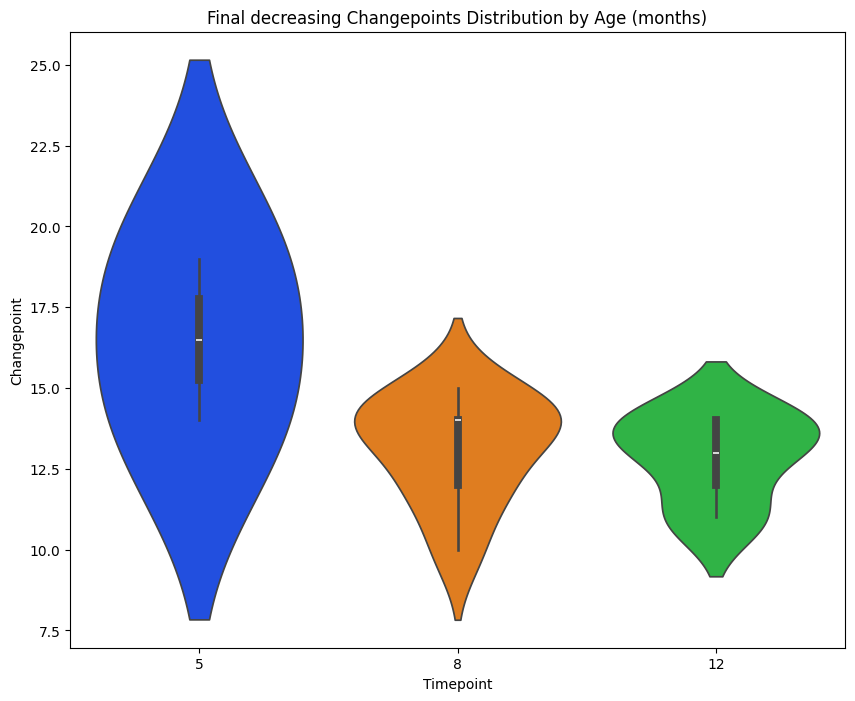

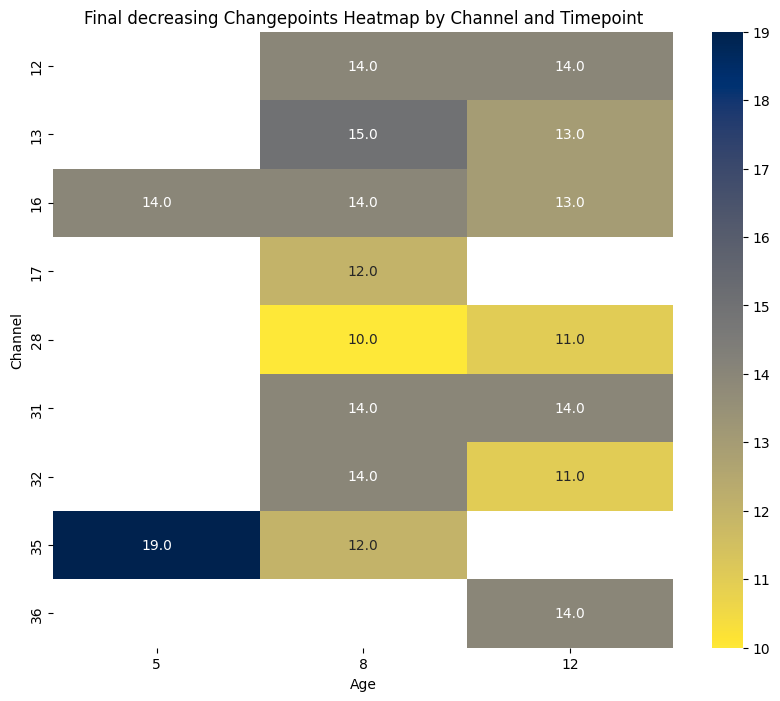

In [198]:
# Violin plot and heatmaps for decreasing AND final change points across ages

#VIOLIN PLOT
# Filter out rows where ChangepointTrial is 0 or NaN
df_filtered = df.dropna(subset=['ChangepointTrial']).loc[df['ChangepointTrial'] != 0]
# Colorblind-friendly palette for violin plot
palette_violin = sns.color_palette("bright", 3)
# Plot violin plot 
plt.figure(figsize=(10, 8))
sns.violinplot(x='Timepoint', y='ChangepointTrial', data=df_filtered, palette=palette_violin)
plt.title('Final decreasing Changepoints Distribution by Age (months)')
plt.ylabel('Changepoint')
plt.show()


# HEATMAP
# Replace 'Channel' numbers with 'BRIGHT' labels
df['BRIGHT'] = df['Channel'].map(mappingDict)
# Pivot table for heatmap using BRIGHT labels
pivot_table = df.pivot_table(index='BRIGHT', columns='Timepoint', values='ChangepointTrial', aggfunc=np.mean)
# Replace 0s with NaNs
pivot_table_no_zeros = pivot_table.replace(0, np.nan)
# Sort rows based on BRIGHT numbering
pivot_table_no_zeros = pivot_table_no_zeros.sort_index()
# Colorblind-friendly palette for heatmap
paletteHeatmap = 'cividis_r' 
# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(pivot_table_no_zeros, cmap=paletteHeatmap, annot=True, fmt='.1f', cbar=True)
plt.title('Final decreasing Changepoints Heatmap by Channel and Timepoint')
plt.xlabel('Age')
plt.ylabel('Channel')
plt.show()

In [199]:
# Earliest detected Decreasing CPt data  - weighted logistic regression, Post-hoc tests, multiple comparisons and Effect size calculations

print("STATISTICAL ANALYSIS FOR: Earliest detected decreasing CPt data")
print(" ")

# GENERATE DATA IN REQUISITE FORM
# Assuming data already in the format described, modify as needed

# Create count of participants' contributions to each channel data
count = np.empty(len(all_earliestDecrChangePoints))
for i in range(0, len(all_earliestDecrChangePoints)):
    iAge = all_earliestDecrChangePoints.iloc[i]['Age']
    iChan = all_earliestDecrChangePoints.iloc[i]['Channel']
    count[i] = countPartChan_dict[iAge][iChan-1].astype(int)

data = {
    'Channel': all_earliestDecrChangePoints['Channel'].values.astype(int),
    'Timepoint': all_earliestDecrChangePoints['Age'].values.astype(int),
    'ChangepointTrial': all_earliestDecrChangePoints['Change Point'].values.astype(int),
    'NumberOfParticipants': count,
    'Change Point Count': all_earliestDecrChangePoints['Change Point Count'].values.astype(int)
}

# Create DataFrame
df = pd.DataFrame(data)

# # Print sample of the generated data (to check!)
# print("Sample of Generated Data:")
# print(df.head())
# print()

# Ordinal Logistic Regression with weights
model_ologit = OrderedModel(df['ChangepointTrial'], 
                            df[['Timepoint', 'Change Point Count']], 
                            weights=df['NumberOfParticipants'], 
                            distr='logit')
result_ologit = model_ologit.fit(method='bfgs')

# Print original results for the weighted ordinal logistic regression
print("Weighted Ordinal Logistic Regression:")
print(result_ologit.summary()) #full
print()

# # Correct effect of timepoint for multiple comparisons
# pvalues = result_ologit.pvalues
# alpha = 0.05
# reject, pvals_corrected, _, _ = multipletests(pvalues, alpha=alpha, method='h')
# print("Bonferroni corrected p-value for Age ('Timepoint'):")
# print(pvals_corrected[0])
# print()

# Perform Wald test for the 'Timepoint' coefficient
wald_test_timepoint = result_ologit.wald_test('Timepoint')
print("Outcome of conducting a post-hoc Wald test:")
print("(to confirm that age has a significant effect on the changepoints detected)")
print(wald_test_timepoint)
print()

# Fit an OLS model for ANOVA
anova_model = ols('ChangepointTrial ~ C(Timepoint)', data=df).fit()

# Perform Tukey's HSD test for multiple comparisons
tukey_results = pairwise_tukeyhsd(endog=df['ChangepointTrial'], 
                                  groups=df['Timepoint'], 
                                  alpha=0.05)
print(tukey_results)


# # Predict probabilities for each category
# pred_probs = result_ologit.predict()

# # Add predicted probabilities to the DataFrame
# df['Predicted_Probabilities'] = pred_probs.tolist()

# # Example: Calculate marginal effects for a specific Timepoint (say, 5)
# df_timepoint_5 = df[df['Timepoint'] == 5].copy()

# # Predict probabilities for Timepoint 5
# pred_probs_timepoint_5 = result_ologit.predict(df_timepoint_5[['Timepoint', 'Channel']])

# # Calculate the difference in predicted probabilities for Timepoint 5
# marginal_effect_timepoint_5 = pred_probs_timepoint_5.mean(axis=0) - pred_probs.mean(axis=0)

# print(f"Marginal Effects for Timepoint 5:\n{marginal_effect_timepoint_5}")




STATISTICAL ANALYSIS FOR: Earliest detected decreasing CPt data
 
Optimization terminated successfully.
         Current function value: 2.303571
         Iterations: 33
         Function evaluations: 35
         Gradient evaluations: 35
Weighted Ordinal Logistic Regression:
                             OrderedModel Results                             
Dep. Variable:       ChangepointTrial   Log-Likelihood:                -46.071
Model:                   OrderedModel   AIC:                             118.1
Method:            Maximum Likelihood   BIC:                             131.1
Date:                Sun, 23 Feb 2025                                         
Time:                        16:50:08                                         
No. Observations:                  20                                         
Df Residuals:                       7                                         
Df Model:                           2                                         
             

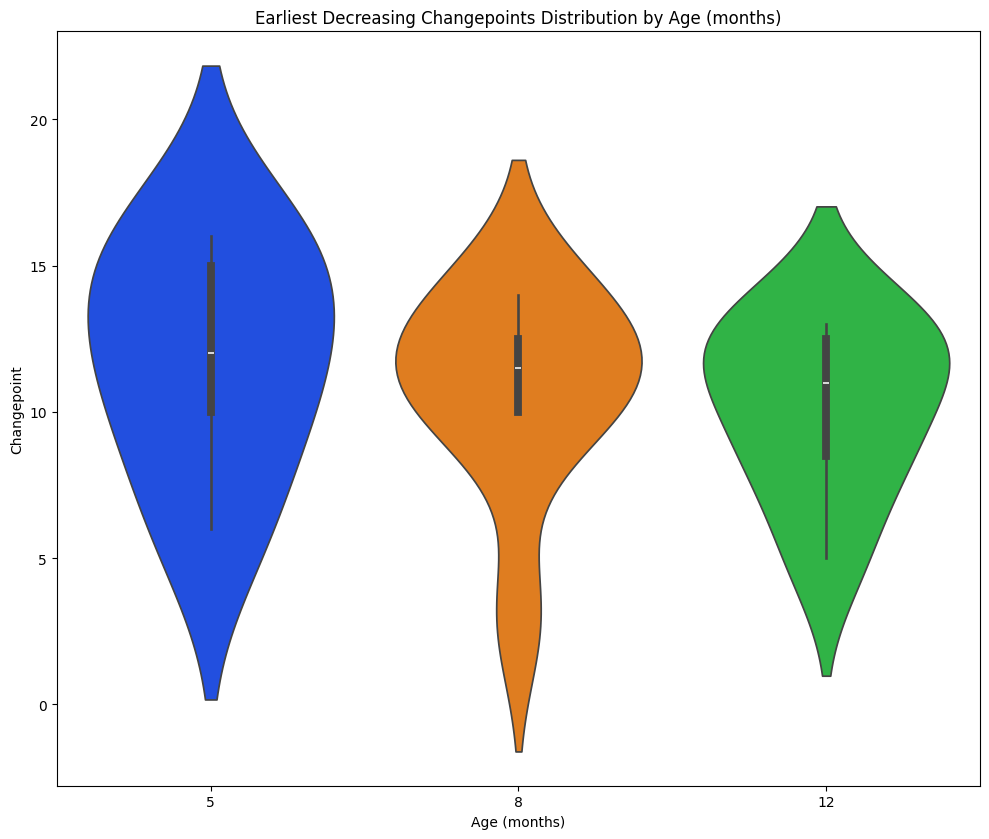

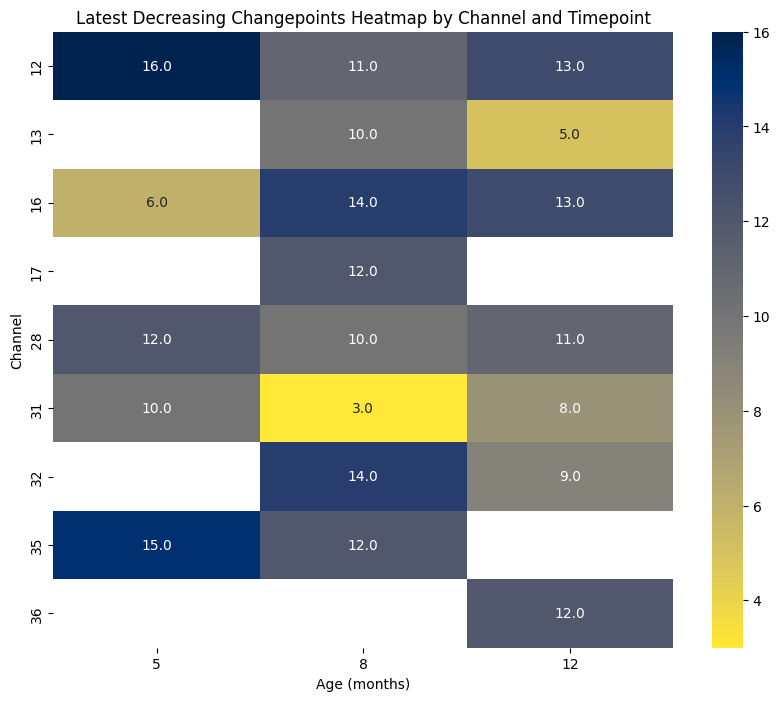

In [ ]:
# Violin plot and heatmaps for earliest decreasing change point across ages


# VIOLIN PLOT
# Filter out rows where ChangepointTrial is 0 or NaN
df_filtered = df.dropna(subset=['ChangepointTrial']).loc[df['ChangepointTrial'] != 0]
# Colorblind-friendly palette for violin plot
palette_violin = sns.color_palette("bright", 3)
# Plot violin plot 
plt.figure(figsize=(10, 8.5))
ax = sns.violinplot(x='Timepoint', y='ChangepointTrial', data=df_filtered, palette=palette_violin)
plt.title('Earliest Decreasing Changepoints Distribution by Age (months)')
plt.xlabel('Age (months)')
plt.ylabel('Changepoint')


plt.tight_layout()
plt.show()



# HEATMAP
# Replace 'Channel' numbers with 'BRIGHT' labels
df['BRIGHT'] = df['Channel'].map(mappingDict)
# Pivot table for heatmap using BRIGHT labels
pivot_table = df.pivot_table(index='BRIGHT', columns='Timepoint', values='ChangepointTrial', aggfunc=np.mean)
# Replace 0s with NaNs
pivot_table_no_zeros = pivot_table.replace(0, np.nan)
# Sort rows based on BRIGHT numbering
pivot_table_no_zeros = pivot_table_no_zeros.sort_index()
# Colorblind-friendly palette for heatmap
paletteHeatmap = 'cividis_r' 
# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(pivot_table_no_zeros, cmap=paletteHeatmap, annot=True, fmt='.1f', cbar=True)
plt.title('Earliest Decreasing Changepoints Heatmap by Channel and Timepoint')
plt.xlabel('Age (months)')
plt.ylabel('Channel')
plt.show()


In [201]:
# Latest detected Decreasing CPt data  - weighted logistic regression, Post-hoc tests, multiple comparisons and Effect size calculations
print("STATISTICAL ANALYSIS FOR: Latest detected decreasing CPt data")
print(" ")

# GENERATE DATA IN REQUISITE FORM
# Assuming data already in the format described, modify as needed

# Create count of participants' contributions to each channel data
count = np.empty(len(all_latestDecrChangePoints))
for i in range(0, len(all_latestDecrChangePoints)):
    iAge = all_latestDecrChangePoints.iloc[i]['Age']
    iChan = all_latestDecrChangePoints.iloc[i]['Channel']
    count[i] = countPartChan_dict[iAge][iChan-1].astype(int)

data = {
    'Channel': all_latestDecrChangePoints['Channel'].values.astype(int),
    'Timepoint': all_latestDecrChangePoints['Age'].values.astype(int),
    'ChangepointTrial': all_latestDecrChangePoints['Change Point'].values.astype(int),
    'NumberOfParticipants': count,
    'Change Point Count': all_latestDecrChangePoints['Change Point Count'].values.astype(int)
}

# Create DataFrame
df = pd.DataFrame(data)

# # Print sample of the generated data (to check!)
# print("Sample of Generated Data:")
# print(df.head())
# print()

# Ordinal Logistic Regression with weights
model_ologit = OrderedModel(df['ChangepointTrial'], 
                            df[['Timepoint', 'Change Point Count']], 
                            weights=df['NumberOfParticipants'], 
                            distr='logit')
result_ologit = model_ologit.fit(method='bfgs')

# Print original results for the weighted ordinal logistic regression
print("Weighted Ordinal Logistic Regression:")
print(result_ologit.summary()) #full
print()

# # Correct effect of timepoint for multiple comparisons
# pvalues = result_ologit.pvalues
# alpha = 0.05
# reject, pvals_corrected, _, _ = multipletests(pvalues, alpha=alpha, method='bonferroni')
# print("Bonferroni corrected p-value for Age ('Timepoint'):")
# print(pvals_corrected[0])
# print()

# Perform Wald test for the 'Timepoint' coefficient
wald_test_timepoint = result_ologit.wald_test('Timepoint')
print("Outcome of conducting a post-hoc Wald test:")
print("(to confirm that age has a significant effect on the changepoints detected)")
print(wald_test_timepoint)
print()

# Fit an OLS model for ANOVA
anova_model = ols('ChangepointTrial ~ C(Timepoint)', data=df).fit()

# Perform Tukey's HSD test for multiple comparisons
tukey_results = pairwise_tukeyhsd(endog=df['ChangepointTrial'], 
                                  groups=df['Timepoint'], 
                                  alpha=0.05)
print(tukey_results)


# # Predict probabilities for each category
# pred_probs = result_ologit.predict()

# # Add predicted probabilities to the DataFrame
# df['Predicted_Probabilities'] = pred_probs.tolist()

# # Example: Calculate marginal effects for a specific Timepoint (say, 5)
# df_timepoint_5 = df[df['Timepoint'] == 5].copy()

# # Predict probabilities for Timepoint 5
# pred_probs_timepoint_5 = result_ologit.predict(df_timepoint_5[['Timepoint', 'Channel']])

# # Calculate the difference in predicted probabilities for Timepoint 5
# marginal_effect_timepoint_5 = pred_probs_timepoint_5.mean(axis=0) - pred_probs.mean(axis=0)

# print(f"Marginal Effects for Timepoint 5:\n{marginal_effect_timepoint_5}")



STATISTICAL ANALYSIS FOR: Latest detected decreasing CPt data
 
Optimization terminated successfully.
         Current function value: 1.759072
         Iterations: 30
         Function evaluations: 32
         Gradient evaluations: 32
Weighted Ordinal Logistic Regression:
                             OrderedModel Results                             
Dep. Variable:       ChangepointTrial   Log-Likelihood:                -35.181
Model:                   OrderedModel   AIC:                             88.36
Method:            Maximum Likelihood   BIC:                             97.32
Date:                Sun, 23 Feb 2025                                         
Time:                        16:50:08                                         
No. Observations:                  20                                         
Df Residuals:                      11                                         
Df Model:                           2                                         
               

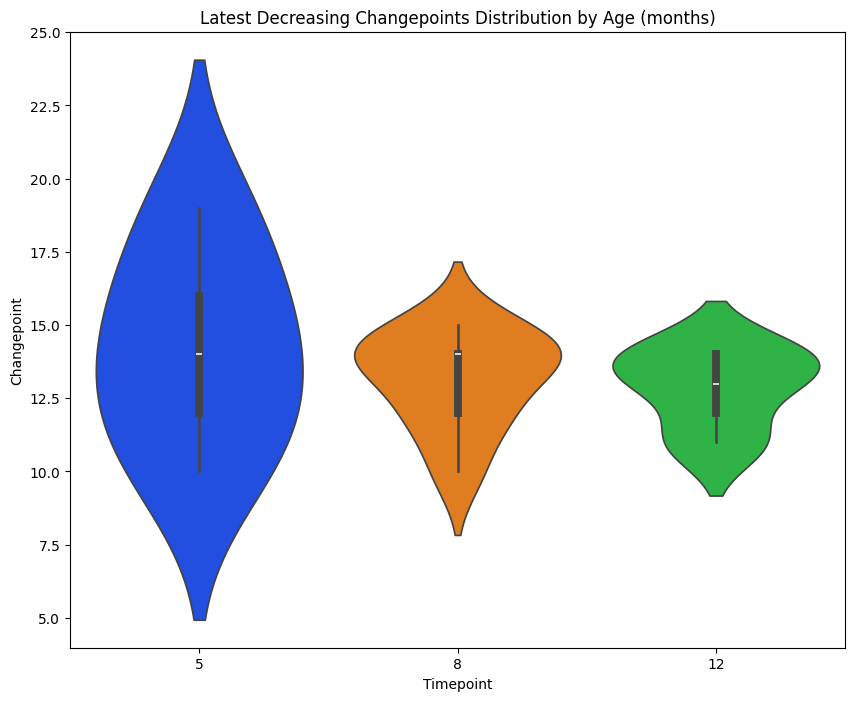

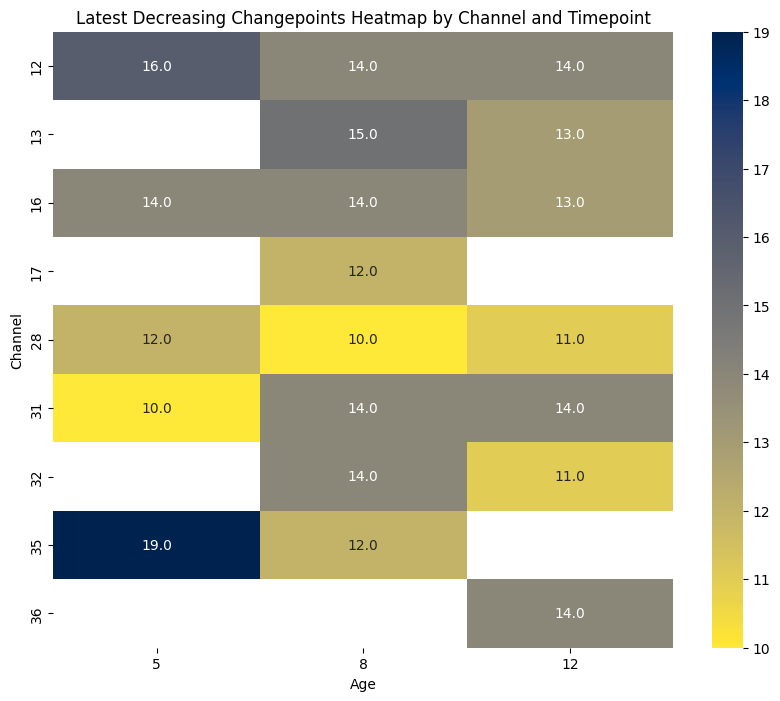

In [202]:
# Violin plot and heatmaps for latest decreasing change point across ages

#VIOLIN PLOT
# Filter out rows where ChangepointTrial is 0 or NaN
df_filtered = df.dropna(subset=['ChangepointTrial']).loc[df['ChangepointTrial'] != 0]
# Colorblind-friendly palette for violin plot
palette_violin = sns.color_palette("bright", 3)
# Plot violin plot 
plt.figure(figsize=(10, 8))
sns.violinplot(x='Timepoint', y='ChangepointTrial', data=df_filtered, palette=palette_violin)
plt.title('Latest Decreasing Changepoints Distribution by Age (months)')
plt.ylabel('Changepoint')
plt.show()



# HEATMAP
# Replace 'Channel' numbers with 'BRIGHT' labels
df['BRIGHT'] = df['Channel'].map(mappingDict)
# Pivot table for heatmap using BRIGHT labels
pivot_table = df.pivot_table(index='BRIGHT', columns='Timepoint', values='ChangepointTrial', aggfunc=np.mean)
# Replace 0s with NaNs
pivot_table_no_zeros = pivot_table.replace(0, np.nan)
# Sort rows based on BRIGHT numbering
pivot_table_no_zeros = pivot_table_no_zeros.sort_index()
# Colorblind-friendly palette for heatmap
paletteHeatmap = 'cividis_r' 
# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(pivot_table_no_zeros, cmap=paletteHeatmap, annot=True, fmt='.1f', cbar=True)
plt.title('Latest Decreasing Changepoints Heatmap by Channel and Timepoint')
plt.xlabel('Age')
plt.ylabel('Channel')
plt.show()
